# Jämförelse mellan MLP och CNN för bildklassifiering

Denna notebook jämför två neurala nätverksarkitekturer för bildklassifiering. Ett multi-layer perceptron(MLP) och ett Convolutional Neural Network(CNN).

Enligt uppgiftsbeskrivningen har vi valt att använda datamängden Fashion-MNIST. Datasetet valdes eftersom det innehåller mer varierande visuella mönster än det klassiska MNIST-datasetet med handskrivna siffror. Syftet består av att undersöka hur olika neurala nätverksarkitekturer påverkar modellens prestanda, generaliseringsförmåga och träningsbeteende.

Import av biblotek

In [ ]:
import numpy as np    #för matematiska beräkningar
import torch
import torch.nn as nn   #innehåller nn.Linear för MLP och nn.Conv2d för CNN
import torch.nn.functional  #innehåller aktiveringsfunktionen relu och pooling
import torch.optim as optim   #innehåller optimerare som t.ex. som Adam som uppdaterar modellens vikter
from torch.utils.data import DataLoader, TensorDataset    #för att dela upp data i batches
import matplotlib.pyplot as plt   #rita grafer

# Hämta datasetet som finns i bibloteket och konvertera bilderna till
import torchvision
import torchvision.transforms as transforms

# För analys och förberedelse
import seaborn as sns
from sklearn.model_selection import train_test_split    #dela upp tränings och valideringsset
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score  #utvärdera hur bra modellerna gissar

# Definiera vilken enhet som ska användas för beräkningar
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



Förbehandling av data

In [ ]:
# 1. Definiera transformationer

# gör om bilderna till Tensors (PyTorchs format) och normaliserar pixelvärdena
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# 2. Ladda ner tränings- och testdata
train_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# 3. Skapa DataLoaders
from torch.utils.data import random_split

train_size = int(0.9 * len(train_dataset)) #90% till att träna modellen
val_size = len(train_dataset) - train_size #resten till validering

train_subset, val_subset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Text-mappning för Fashion-MNIST (eftersom labels är siffror 0-9)
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"Data nedladdad! Träningsbilder: {len(train_dataset)}, Testbilder: {len(test_dataset)}")

Data nedladdad! Träningsbilder: 60000, Testbilder: 10000


-Här hämtar vi ett dataset som består av bilder på olika klädesplagg. 60 000 för ett träningset och 10 000 för ett test set.

-Här hämtar vi och transformerar datan till tensors

-Sedan gör vi våran split, där vi tar 10% av testbilderna åt validering för att ha data till en utvärdering under själva träningen.

-Sedan valde vi också att modellen ska ha en batchsize på 128 bilder. Vi testade att öka antalet för att processen skulle gå snabbare, och märkte ingen större skillnad på resultat från 64 till 128

MLP

In [ ]:
class mlp_model(nn.Module):
    def __init__(self, in_dim=784, hidden=256, out_dim=10):
        # in_dim=784 för att 28x28 pixlar blir 784 värden (platt bild)
        #processa informationen i dolt lager med 128 neuroner i varje
        # out_dim=10 för att vi har 10 klädesplagg
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), # Det dolda lagret
            nn.ReLU(),                 # Aktiveringsfunktionen (icke-linjäritet)
            nn.Linear(hidden, hidden), # Ett extra dolt lager för bättre precision, och bestämmer vad som ska gå till de 10 neuronerna i utgångslagret
            nn.ReLU(),
            nn.Linear(hidden, out_dim) # Output-lagret
        )

    def forward(self, x):
        # Plattar till bilden från (64, 1, 28, 28) till (64, 784)
        #MLP kan bara läsa data på en rad, men bilderna är en fyrkant.
        x = x.view(x.size(0), -1)

        #Skicka datan genom nätverket
        logits = self.net(x)
        return logits

Arkiktekturen:

-ingångslager som tar emot 784 värden (bildens pixlar 28x28)

-två dålda lager

-aktiveringsfunktionen, relu för icke linjäritet.

-utgångslagret av 10 neuroner som representerar datasetet(som har 10 olika klädesplagg).

-Vi valde 256 neuroner då det borde vara tillräckligt många neuroner för att kunna lära sig de viktigaste mönsterna i datasetet, och samtidigt gå relativt snabbt.

MLP setup för träning

In [ ]:
model = mlp_model().to(device) # Flytta modellen till GPU/CPU

# Kostnadsfunktion för klassificering (CrossEntropy) samt softmax inbyggd
#för att räkna ut loss för att kunna bättra på modellen
criterion = nn.CrossEntropyLoss()

# Optimerare, för att uppdatera vikter och en learning rate(hur snabbt modellen ska lära sig)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Listor för att spara statistik till graferna och utskriften
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

Träningsloop, inklusive validering

In [ ]:
  #1. Träningsfas

epochs = 10

for epoch in range(epochs):

    model.train()
    train_run_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()   #nollställa
        outputs = model(images)   #forwardpass, alltså låter modellen gissa på bilderna
        loss = criterion(outputs, labels)   #använder loss funktionen
        loss.backward()   #räkna ut hur vikterna bör ändras för att minska felet
        optimizer.step()    #uppdatera vikterna

        train_run_loss += loss.item() #adderar varje loss för varje batch
        _, predicted = torch.max(outputs.data, 1)   #typ en Argmax, som hittar högsta poängen för en bild och sparar dess index
        train_total += labels.size(0)   #totala bilder vi gått igenom
        train_correct += (predicted == labels).sum().item()   #hur många rätt, gissningar vs. facit

    #2. Valideringsfas

    model.eval() # Sätt modellen i utvärderingsläge
    val_run_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad(): # Inaktiverar beräkning av gradients, behövs ej vid validering
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)   #modellen gissar
            loss = criterion(outputs, labels)

            val_run_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    #3. Spara statistik

    # Träning
    epoch_train_loss = train_run_loss / len(train_loader)
    epoch_train_acc = 100 * train_correct / train_total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Validering
    epoch_val_loss = val_run_loss / len(val_loader)
    epoch_val_acc = 100 * val_correct / val_total
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"  Train -> Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_acc:.2f}%")
    print(f"  Val   -> Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_acc:.2f}%")

Epoch [1/10]
  Train -> Loss: 0.5180, Acc: 81.11%
  Val   -> Loss: 0.4586, Acc: 83.63%
Epoch [2/10]
  Train -> Loss: 0.3798, Acc: 86.06%
  Val   -> Loss: 0.4067, Acc: 85.08%
Epoch [3/10]
  Train -> Loss: 0.3369, Acc: 87.56%
  Val   -> Loss: 0.3829, Acc: 86.08%
Epoch [4/10]
  Train -> Loss: 0.3113, Acc: 88.35%
  Val   -> Loss: 0.3466, Acc: 87.45%
Epoch [5/10]
  Train -> Loss: 0.2926, Acc: 89.00%
  Val   -> Loss: 0.3189, Acc: 88.68%
Epoch [6/10]
  Train -> Loss: 0.2746, Acc: 89.68%
  Val   -> Loss: 0.3380, Acc: 87.87%
Epoch [7/10]
  Train -> Loss: 0.2596, Acc: 90.21%
  Val   -> Loss: 0.3122, Acc: 88.50%
Epoch [8/10]
  Train -> Loss: 0.2478, Acc: 90.65%
  Val   -> Loss: 0.3135, Acc: 88.93%
Epoch [9/10]
  Train -> Loss: 0.2359, Acc: 91.11%
  Val   -> Loss: 0.3080, Acc: 89.22%
Epoch [10/10]
  Train -> Loss: 0.2239, Acc: 91.42%
  Val   -> Loss: 0.3363, Acc: 88.18%


Val av hyperparametrar och ananlys av träning:
-----------------

-Vi har alltså använt torch_max för att ta fram accuracy , genom att ta rätt matchningar delat på antal bilder.

-Sedan har vi använt oss av crossentrypy för att ta fram loss, vilket är en standard metod för klassificering(speciellt med flera klasser). Den är bra eftersom den räknar ut hur osäker modellen är och berättar vad som behövs för att optimera den.

-Vi använde optimeraren Adam, den har ett förinställt standardvärde på 0,001, och det som är bra är att den är självjusterande. Detta för en stabilare modell. Verkar dock hoppa lite mellan epokerna. Vilket kan betyda att learning raten möjligtvis blivit för hög, alltså att den tar för stora steg ibland vilket gör att den missar den optimala inställningen

-När de kommer till valet av epoker, så valde vi 10 st. med valideringsfasen kan vi  se att redan efter epok 5 kan man se skillnader mellan traning och validation loss. Medans traning loss minskar, ökar istället valideringsfelet. Vilket visar tecken på tidig överanpassning. Generaliseringen verkar vara bäst innan överanpassningen sker.

-Träningstid via cpu - 2,30min, gpu 2 min

Visualisering

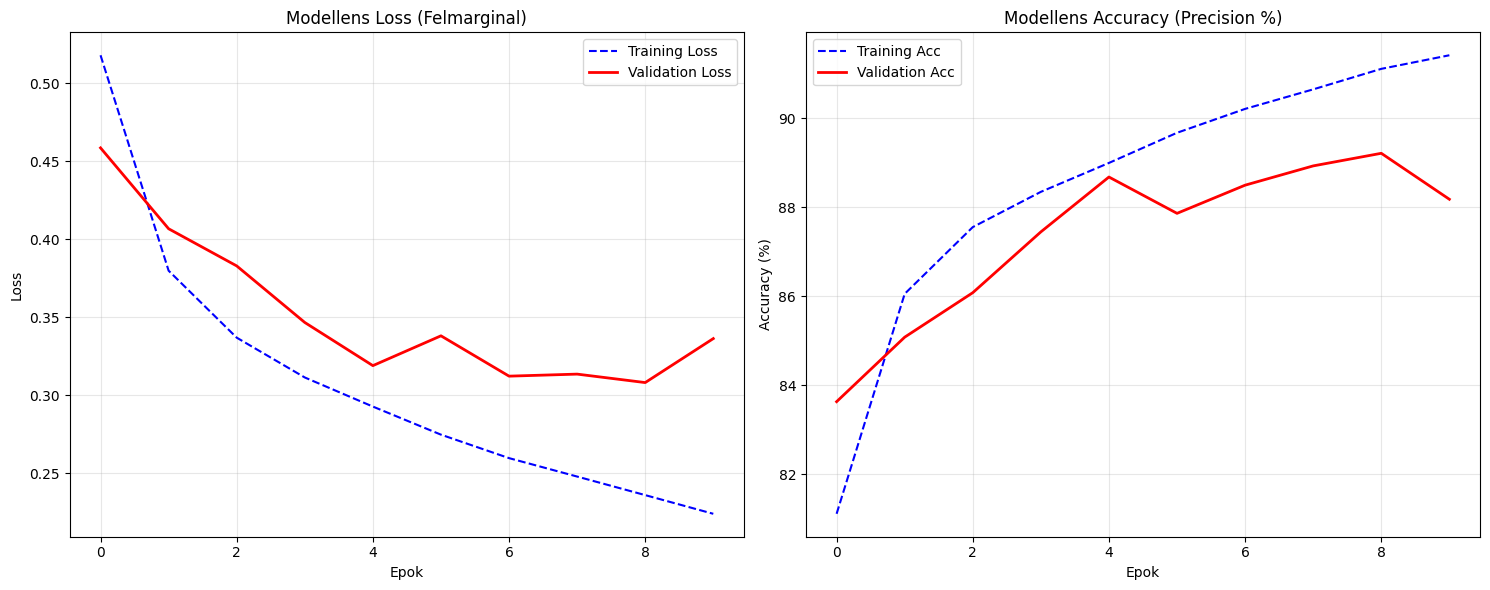

In [ ]:
# Skapa en figur med plats för två grafer
plt.figure(figsize=(15, 6))

#Graf 1: Loss (Träning vs Validering)
plt.subplot(1, 2, 1)    #Skapa en tabell med 1 rad, 2 kolumner, och rita i den första (vänstra) rutan
plt.plot(train_losses, label='Training Loss', color='blue', linestyle='--')
plt.plot(val_losses, label='Validation Loss', color='red', linewidth=2)
plt.title('Modellens Loss (Felmarginal)')
plt.xlabel('Epok')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)   #svagt rutnät

#Graf 2: Accuracy (Träning vs Validering)
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Acc', color='blue', linestyle='--')
plt.plot(val_accuracies, label='Validation Acc', color='red', linewidth=2)
plt.title('Modellens Accuracy (Precision %)')
plt.xlabel('Epok')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()    #För att graferna inte ska överlappa varandra
plt.show()

Här kan man se på graferna att de inte följer varandra riktigt. I loss grafen kan man se att den hoppar men utöver de så blir inte val_loss grafen lika låg som training loss och stiger istället, vilket visar på tidigt överanpassning .

Test

In [ ]:
# 1. Sätt modellen i utvärderingsläge utan
model.eval()

test_run_loss = 0.0  # Ny rad för att samla total loss
test_correct = 0
test_total = 0

# 2. Starta test (utan beräkning av gradients)
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)   #modellen gissar
        loss = criterion(outputs, labels)

        test_run_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

# 3. Beräkna genomsnittlig loss och accuracy
final_test_loss = test_run_loss / len(test_loader)
final_test_acc = 100 * test_correct / test_total

print(f"Slutgiltigt resultat på Test-datasetet (MLP):")
print(f"  Loss:     {final_test_loss:.4f}")
print(f"  Accuracy: {final_test_acc:.2f}%")

Slutgiltigt resultat på Test-datasetet (MLP):
  Loss:     0.3544
  Accuracy: 88.00%


slut resultat (dock inte med den bäst generaliserade modellen från träningsloopen)

CNN - struktur

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  #konvolutionslager som drar 16 olika filter över bilden
            nn.ReLU(),
            nn.MaxPool2d(2),   #pooling lager, där bildens storlek halveras från 28x28 -> 14x14

            nn.Conv2d(16, 32, kernel_size=3, padding=1),    #konvolutionslager 2, med 32 filter
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(32 * 7 * 7, 128),   #fulltkopplat lager. Här kopplar vi  produkten av datapunkterna till 128 neuroner
            nn.ReLU(),
            nn.Linear(128, 10)    #omvandlar de 128 neuroenra till 10 värden för varje klädesplagg
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

Ariktektur:

-Två konvolutionslager: Där det första lagret skapar 16 filter och det andra 32 för att identifiera mönster såsom kanter och former på kläderna. Med två lager kan man identifiera mer komplexa mönster.

-Två pooling lager: Halverar bildens dimensioner. Från 28x28 till 7x7. Som behåller de viktigaste mönstren men dessutom minskar chansen för överanpassning.

-aktiverings funktionen

-Fullt kopplat lager som tittar på alla värden från konvultionslagern. Vilket gör en slutsats på vad modellen hittat för värden

 CNN setup

In [ ]:
cnn_model = CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

cnn_train_losses = []
cnn_train_accuracies = []

cnn_val_losses = []
cnn_val_accuracies = []

CNN - träningsloop

In [ ]:
  #1. Träningsfas

epochs = 10

for epoch in range(epochs):

    cnn_model.train()
    train_run_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_run_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    #2. Valideringsfas

    cnn_model.eval()
    val_run_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_run_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    #3. Spara statistik

    # Träning
    epoch_train_loss = train_run_loss / len(train_loader)
    epoch_train_acc = 100 * train_correct / train_total
    cnn_train_losses.append(epoch_train_loss)
    cnn_train_accuracies.append(epoch_train_acc)

    # Validering
    epoch_val_loss = val_run_loss / len(val_loader)
    epoch_val_acc = 100 * val_correct / val_total
    cnn_val_losses.append(epoch_val_loss)
    cnn_val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"  Train -> Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_acc:.2f}%")
    print(f"  Val   -> Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_acc:.2f}%")


Epoch [1/10]
  Train -> Loss: 0.5445, Acc: 80.40%
  Val   -> Loss: 0.4099, Acc: 85.38%
Epoch [2/10]
  Train -> Loss: 0.3451, Acc: 87.57%
  Val   -> Loss: 0.3307, Acc: 88.17%
Epoch [3/10]
  Train -> Loss: 0.2970, Acc: 89.22%
  Val   -> Loss: 0.3071, Acc: 88.35%
Epoch [4/10]
  Train -> Loss: 0.2683, Acc: 90.14%
  Val   -> Loss: 0.2814, Acc: 89.78%
Epoch [5/10]
  Train -> Loss: 0.2461, Acc: 90.99%
  Val   -> Loss: 0.2680, Acc: 90.38%
Epoch [6/10]
  Train -> Loss: 0.2267, Acc: 91.65%
  Val   -> Loss: 0.2588, Acc: 90.77%
Epoch [7/10]
  Train -> Loss: 0.2105, Acc: 92.10%
  Val   -> Loss: 0.2510, Acc: 91.15%
Epoch [8/10]
  Train -> Loss: 0.1960, Acc: 92.71%
  Val   -> Loss: 0.2346, Acc: 91.70%
Epoch [9/10]
  Train -> Loss: 0.1823, Acc: 93.18%
  Val   -> Loss: 0.2383, Acc: 91.78%
Epoch [10/10]
  Train -> Loss: 0.1678, Acc: 93.74%
  Val   -> Loss: 0.2392, Acc: 91.68%


-Samma träningsloop, för CNN, vi delade upp det för att enklare kunna jämföra.

-Vi kan här konstantera att CNN har presterat bättre än MLP när de kommer till att vara självsäker (mindre loss) och accuracy.

-Det är som sagt samma hyperparamterar och loop, och efter epok 8 så ser vi att train lossen fortsätter sjunka medans val loss ökar efter. Detta visar också på överanpassning, men träningen verkar mer stabil än MLP modellen.

-Träningstid via cpu - 7min, gpu 3 min

Visualisering för CNN

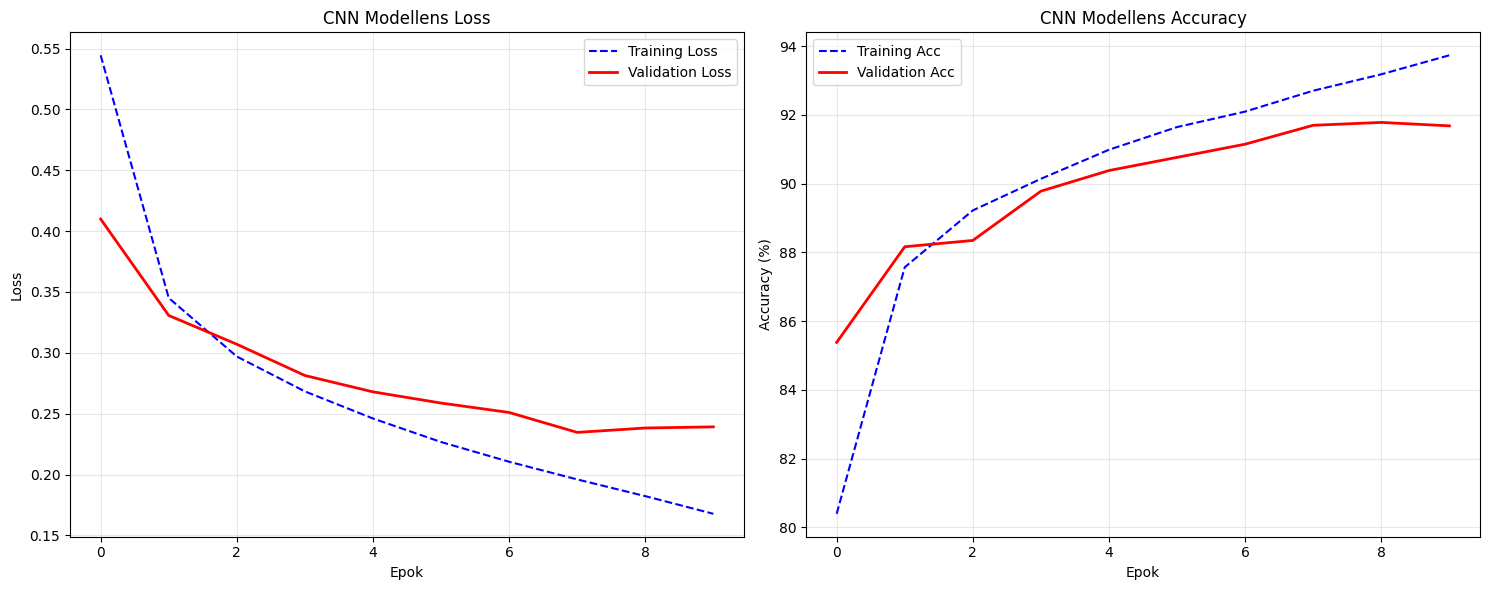

In [ ]:
# Skapa en figur med två grafer
plt.figure(figsize=(15, 6))

# --- Graf 1: Loss (Träning vs Validering) ---
plt.subplot(1, 2, 1)
plt.plot(cnn_train_losses, label='Training Loss', color='blue', linestyle='--')
plt.plot(cnn_val_losses, label='Validation Loss', color='red', linewidth=2)
plt.title('CNN Modellens Loss')
plt.xlabel('Epok')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# --- Graf 2: Accuracy (Träning vs Validering) ---
plt.subplot(1, 2, 2)
plt.plot(cnn_train_accuracies, label='Training Acc', color='blue', linestyle='--')
plt.plot(cnn_val_accuracies, label='Validation Acc', color='red', linewidth=2)
plt.title('CNN Modellens Accuracy')
plt.xlabel('Epok')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Här kan man se på graferna är mycket mer lika än i jämförelse med träningsloopen på MLP. Och överpassningen börjar visa sig efter 7-8.

CNN - test

In [ ]:
# 1. Sätt modellen i utvärderingsläge
cnn_model.eval()

test_run_loss = 0.0
test_correct = 0
test_total = 0

# 2. Inaktivera gradienter
with torch.no_grad():
    for images, labels in test_loader:

        # Flytta data till GPU/CPU
        images, labels = images.to(device), labels.to(device)

        # Framåtpass
        outputs = cnn_model(images)

        # Beräkna loss
        loss = criterion(outputs, labels)
        test_run_loss += loss.item()

        # Hämta prediction
        _, predicted = torch.max(outputs.data, 1)

        # Summera resultat
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

# 3. Beräkna genomsnittlig loss och accuracy
final_test_loss = test_run_loss / len(test_loader)
final_test_acc = 100 * test_correct / test_total

# Skriv ut slutresultatet
print(f"Slutgiltigt resultat på Test-datasetet (CNN):")
print(f"  Loss:     {final_test_loss:.4f}")
print(f"  Accuracy: {final_test_acc:.2f}%")

Slutgiltigt resultat på Test-datasetet (CNN):
  Loss:     0.2525
  Accuracy: 91.21%


-Lägre loss och högre accuracy än MLP modellen

Parametrar jämförelse mellan MLP och CNN



In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("MLP parameters:", count_parameters(model))
print("CNN parameters:", count_parameters(cnn_model))

MLP parameters: 269322
CNN parameters: 206922


Mer parametrar i MLP modellen!


PRECISION OCH RECALL FÖR MLP
---------------------------------------------
Klass           | Precision    | Recall      
---------------------------------------------
T-shirt         | 0.8044       | 0.8840      
Trouser         | 0.9829       | 0.9770      
Pullover        | 0.7055       | 0.8960      
Dress           | 0.9034       | 0.8880      
Coat            | 0.8341       | 0.7690      
Sandal          | 0.9652       | 0.9430      
Shirt           | 0.8120       | 0.5570      
Sneaker         | 0.9314       | 0.9500      
Bag             | 0.9425       | 0.9840      
Ankle boot      | 0.9473       | 0.9520      
---------------------------------------------
SAMMANLAGT      | 0.8829       | 0.8800      
---------------------------------------------

PRECISION OCH RECALL FÖR CNN
---------------------------------------------
Klass           | Precision    | Recall      
---------------------------------------------
T-shirt         | 0.8812       | 0.8160      
Trouser         | 0.

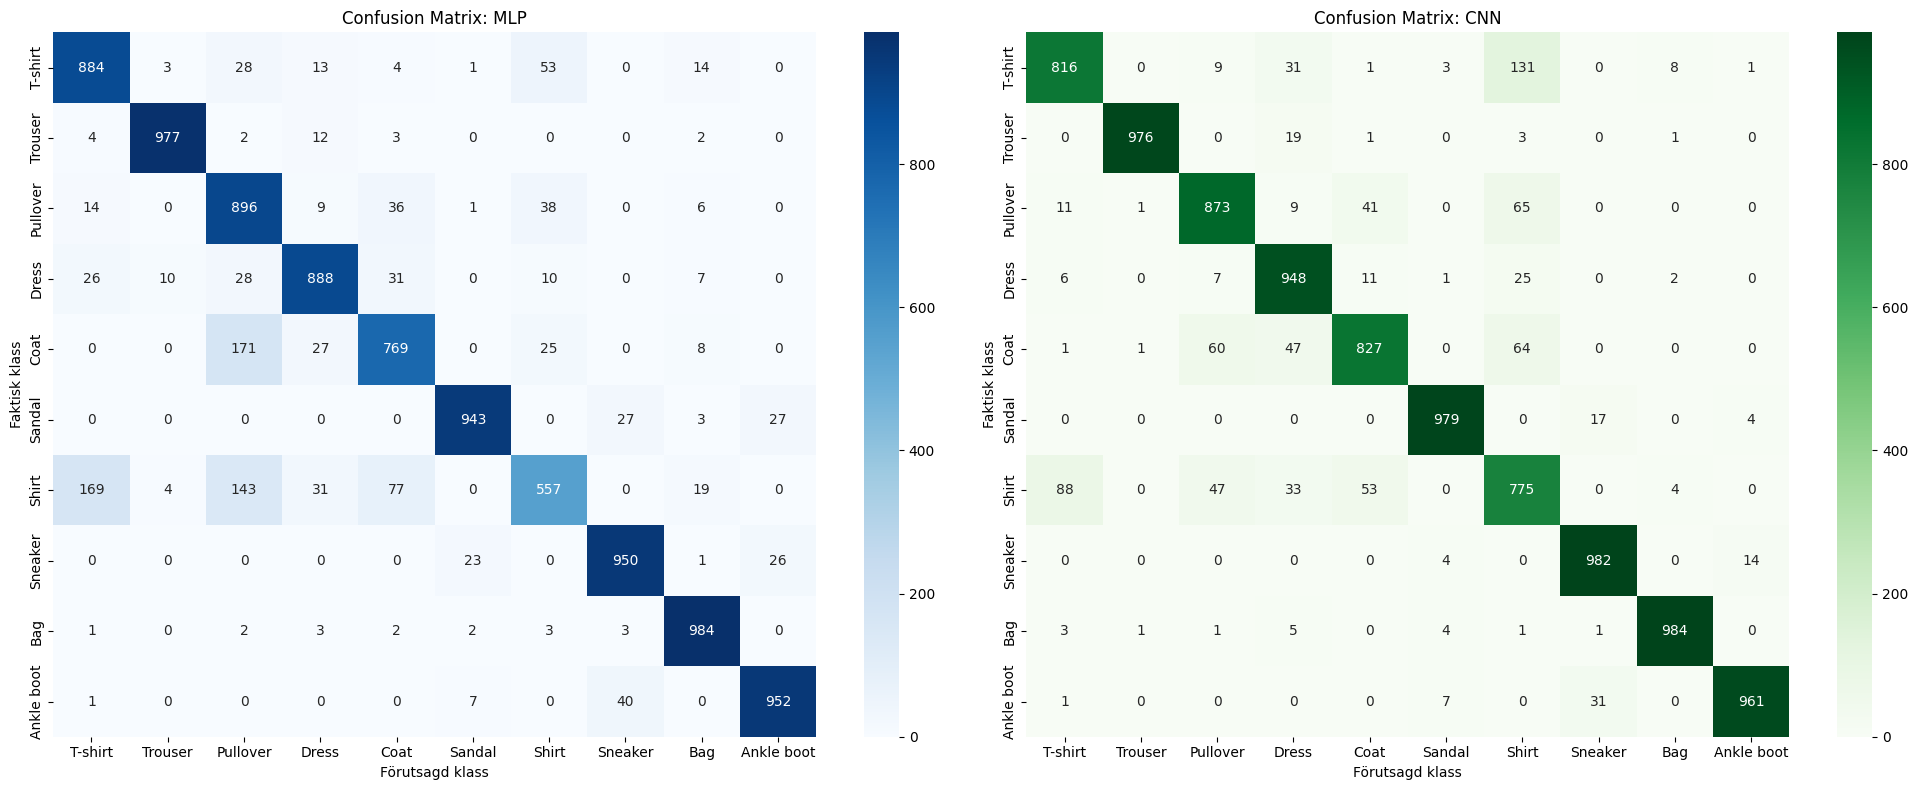

In [ ]:
def plot_confusion_matrices(mlp_model, cnn_model, test_loader, device):
    mlp_model.eval()
    cnn_model.eval()

    all_labels = []
    mlp_preds = []
    cnn_preds = []

    classes = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            # MLP Predictions (måste plattas till)
            mlp_out = mlp_model(images.view(images.size(0), -1))
            mlp_preds.extend(torch.max(mlp_out, 1)[1].cpu().numpy())

            # CNN Predictions
            cnn_out = cnn_model(images)
            cnn_preds.extend(torch.max(cnn_out, 1)[1].cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    # ta fram precision och recall, utvärderingsmått!

    def skriv_ut_precision_recall(labels, preds, modell_namn):
        # Beräkna för varje enskild klass
        prec = precision_score(labels, preds, average=None)
        rec = recall_score(labels, preds, average=None)

        # Beräkna sammanlagda snittet (Macro-average)
        prec_macro = precision_score(labels, preds, average='macro')
        rec_macro = recall_score(labels, preds, average='macro')

        print(f"\n{modell_namn.upper()}")
        print("-" * 45)
        print(f"{'Klass':<15} | {'Precision':<12} | {'Recall':<12}")
        print("-" * 45)
        for i, c in enumerate(classes):
            print(f"{c:<15} | {prec[i]:<12.4f} | {rec[i]:<12.4f}")
        print("-" * 45)
        print(f"{'SAMMANLAGT':<15} | {prec_macro:<12.4f} | {rec_macro:<12.4f}")
        print("-" * 45)

    skriv_ut_precision_recall(all_labels, mlp_preds, "Precision och Recall för MLP")
    skriv_ut_precision_recall(all_labels, cnn_preds, "Precision och Recall för CNN")
    # --------------------------------------------------------

    # Skapa figur med två subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # MLP Matrix
    cm_mlp = confusion_matrix(all_labels, mlp_preds)
    sns.heatmap(cm_mlp, annot=True, fmt='d', ax=ax1, cmap='Blues', xticklabels=classes, yticklabels=classes)
    ax1.set_title('Confusion Matrix: MLP')
    ax1.set_ylabel('Faktisk klass')
    ax1.set_xlabel('Förutsagd klass')

    # CNN Matrix
    cm_cnn = confusion_matrix(all_labels, cnn_preds)
    sns.heatmap(cm_cnn, annot=True, fmt='d', ax=ax2, cmap='Greens', xticklabels=classes, yticklabels=classes)
    ax2.set_title('Confusion Matrix: CNN')
    ax2.set_ylabel('Faktisk klass')
    ax2.set_xlabel('Förutsagd klass')

    plt.tight_layout()
    plt.show()

# Kör funktionen (se till att namnen stämmer med era modeller)
plot_confusion_matrices(model, cnn_model, test_loader, device)














-Här valde vi att skapa en confusian matrix för att enklare kunna tolka vad modellerna va bra på och om det är nån större skillnad mellan de två. På y-axeln har vi facit på vilka klasser bilderna tillhör och x-axeln prediktionerna var modellerna tror de tillhör. (utifrån test datan)

-Det vi ser är att båda modellerna visserligen varit relativt bra på att predikera. Men där CNN varit bättre på att gissa fler rätt sammanlagt om man tittar på recall och precision.

-Båda modellerna hade något svårare med att klassificera överdelar, MLP hade till och med något bättre resultat om man tittar på recall och precision. Men sammanlagt är CNN något bättre på att klassificiera.


Analytisk sammanfattning

- Varför modellen presterar olika?

Anledningen till att modellerna presterat olika beror på att de kollar på bilderna på olika sätt. MLP ser bilden som en platt vektor och kan inte se om pixlarna ligger nära varandra. Vilket gör att den kan ha svårare att se globala samband eller mönster. CNN använder istället filter för att hitta lokala mönster för att särskilja klädes plaggen. I confusian matrixen kan man se att CNN presterar bättre. Överdelar var exemplvis svårare att särskilja mellan varandra för båda modellerna, men CNN hade dock en bättre precision och recall. Den verkar därmed bättre på att särskilja klasser som liknar varandra.

- Tecken på överanpassning?

Vi såg tecken på överanpassning i båda modellerna. Just i dessa två arkitekturer verkade MLP få en tidigare överanpassning och verkade hoppa lite mer. Vilket innebär att den verkade både memorera träningsdatan, men verkade också vara känslig för brus (då den hoppar). Medans CNN verkade ha en mer stabil träning, vilket syntes till i graferna. I jämförelse med resultatet i träningslooperna, verkar vara CNN vara bättre på att generalisera eftersom både train och val loss blev lägre fram tills överanpassningen syntes. Sedan var resultaten i sig bättre än MLP modellen.

- Hur relaterar modelens komplexitet till dess beteende?

Något som märktes i modellernas beteende var att en CNN, när den inte kördes på GPU, tränade betydligt långsammare. MLP modellen tränade däremot nästan dubbelt så snabbt. Samt har CNN modellen mindre antal paramterar i jämförelse till MLP, vilket få en att tro att CNN borde gå snabbare. Men detta kan förklaras av att arkitekturen i CNN-modellen är mer komplex än i MLP-modellen. CNN-modellen innehåller två konvolutionslager där filter appliceras över bilderna, vilket kräver många beräkningar och därför tar längre tid. Medans MLP-modellen gör istället en stor matrismultiplikation för sina neuroner, vilket gör beräkningarna snabbare.Samtidigt visar resultaten att CNN-modellen lyckas göra mer korrekta prediktioner.

-Sammanfattning

 Sammanfattningsvis visar resultaten att CNN-modellen presterade bättre än MLP.modellen. Den generaliserade mer stabilt. Sedan även om båda modellerna visade överanpassning på både modellerna, men det var tydligare i MLP-modellen. Jämförelsen visar även att modellens uppbyggnad har större betydlelse än antalet parametrar. Detta kan vi se när CNN ger bättre resultat, trots den har färre parametrar.